In [2]:
import pandas as pd
import time
import re
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

print("STEP 1: DATA READING, MISSING VALUE IMPUTATION AND SPLITTING ---")
df = pd.read_csv('../data/processed/scaled_readmission_dataset.csv')
target_col = 'readmitted_risk' if 'readmitted_risk' in df.columns else 'readmitted'

# Label Encoding
df[target_col] = df[target_col].replace({'NO': 0, '>30': 1, '<30': 1, 'NO ': 0})
df[target_col] = df[target_col].astype(int)

X = df.drop(columns=[target_col])
y = df[target_col]

# --- 3 CRITICAL CHANGES FOR MEMORY OPTIMIZATION ---

# 1. Dropping ID numbers initially that won't help the model but inflate the table.
columns_to_drop = ['encounter_id', 'patient_nbr'] 
X = X.drop(columns=[col for col in columns_to_drop if col in X.columns])

# 2. Imputing missing data BEFORE the table reaches a massive size.
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
imputer = SimpleImputer(strategy='median')
X[numeric_cols] = imputer.fit_transform(X[numeric_cols])
print("Numerical missing data successfully imputed.")

# 3. Relieving RAM by casting numbers to "int8" (smallest size) while expanding the table via One-Hot Encoding.
X = pd.get_dummies(X, drop_first=True, dtype='int8')

# Cleaning characters in column names that might cause errors
X = X.rename(columns=lambda x: re.sub(r'[\[\]<>]', '_', str(x)))

print("Memory optimization successfully applied.")

# Splitting the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training Set: {X_train.shape}, Test Set: {X_test.shape}")

STEP 1: DATA READING, MISSING VALUE IMPUTATION AND SPLITTING ---
Numerical missing data successfully imputed.
Memory optimization successfully applied.
Training Set: (81412, 4393), Test Set: (20354, 4393)


In [3]:
print("STEP 2: MODEL BEFORE SMOTE (IMBALANCED DATA) ---")
xgb_before = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_before.fit(X_train, y_train)
y_pred_before = xgb_before.predict(X_test)
cm_before = confusion_matrix(y_test, y_pred_before)
print("Training with imbalanced data completed. (Confusion matrix saved in memory for plotting).")

STEP 2: MODEL BEFORE SMOTE (IMBALANCED DATA) ---
Training with imbalanced data completed. (Confusion matrix saved in memory for plotting).


In [4]:
print("STEP 3: DATA BALANCING WITH SMOTE ---")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(f"Training Set After SMOTE: {X_train_smote.shape}")

STEP 3: DATA BALANCING WITH SMOTE ---
Training Set After SMOTE: (87782, 4393)


In [5]:
print("STEP 4: TRAINING 5 DIFFERENT MODELS AND TIME MEASUREMENT ---")
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss')
}

results = []
roc_data = {}
cms = {}

for name, model in models.items():
    print(f"{name} is training... (Please wait)")
    start_time = time.time()
    
    # Training the Model
    model.fit(X_train_smote, y_train_smote)
    end_time = time.time()
    
    train_time = end_time - start_time
    
    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    # Calculating Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    # Saving data for plots
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)
    cms[name] = confusion_matrix(y_test, y_pred)
    
    results.append({
        "Model": name,
        "Accuracy": f"{acc:.4f}",
        "Precision": f"{prec:.4f}",
        "Recall": f"{rec:.4f}",
        "F1-Score": f"{f1:.4f}",
        "AUC": f"{auc:.4f}",
        "Training Time (s)": f"{train_time:.4f}"
    })
print("All models successfully trained!")

STEP 4: TRAINING 5 DIFFERENT MODELS AND TIME MEASUREMENT ---
Logistic Regression is training... (Please wait)
Decision Tree is training... (Please wait)
K-Nearest Neighbors is training... (Please wait)
Random Forest is training... (Please wait)
XGBoost is training... (Please wait)
All models successfully trained!


STEP 5: RESULTS AND VISUALIZATION ---


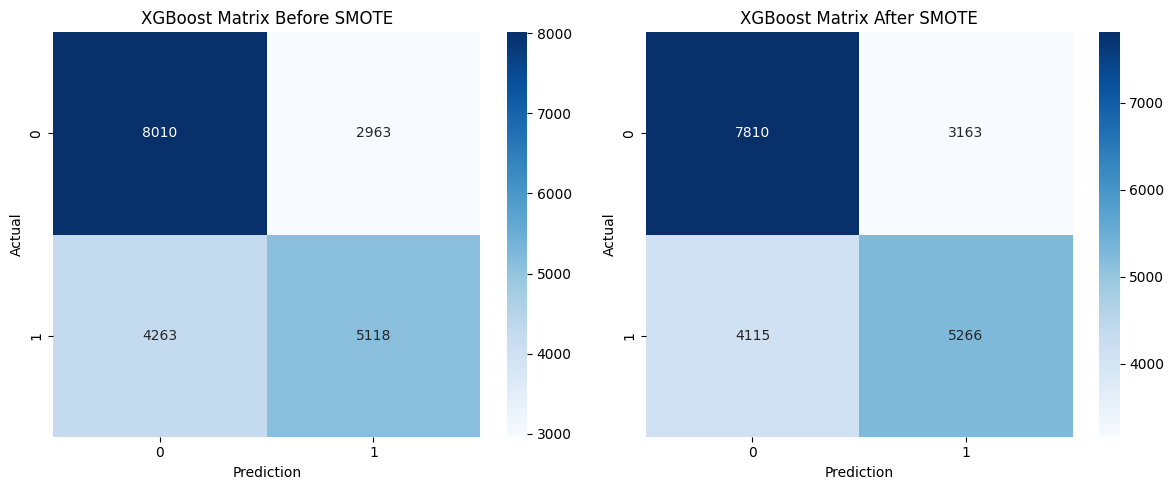

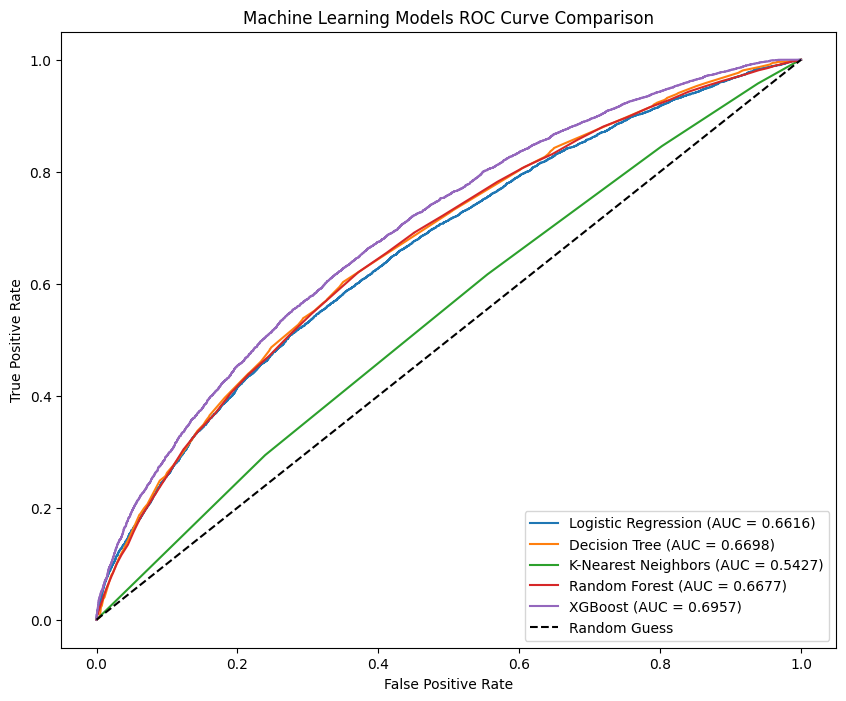

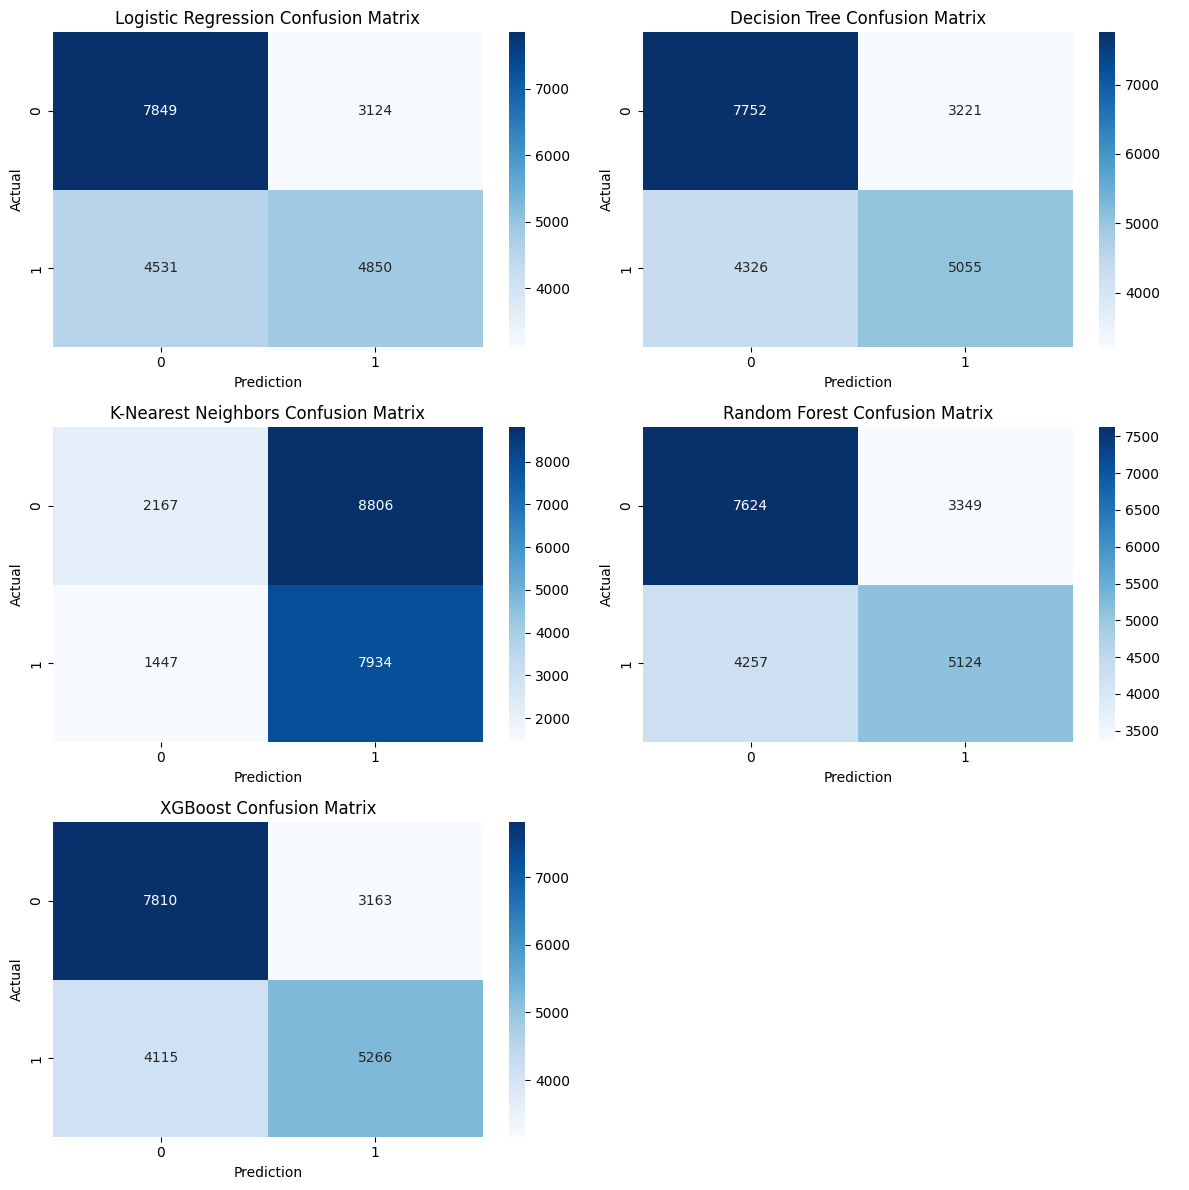


MODEL COMPARISON TABLE ---
              Model Accuracy Precision Recall F1-Score    AUC Training Time (s)
Logistic Regression   0.6239    0.6082 0.5170   0.5589 0.6616          195.2061
      Decision Tree   0.6292    0.6108 0.5389   0.5726 0.6698           19.9703
K-Nearest Neighbors   0.4963    0.4740 0.8458   0.6075 0.5427            4.7561
      Random Forest   0.6263    0.6047 0.5462   0.5740 0.6677           45.0419
            XGBoost   0.6424    0.6247 0.5613   0.5914 0.6957           30.6740


In [6]:
print("STEP 5: RESULTS AND VISUALIZATION ---")

# Figure A: Comparison Before and After SMOTE
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_before, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('XGBoost Matrix Before SMOTE')
axes[0].set_xlabel('Prediction')
axes[0].set_ylabel('Actual')

sns.heatmap(cms['XGBoost'], annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('XGBoost Matrix After SMOTE')
axes[1].set_xlabel('Prediction')
axes[1].set_ylabel('Actual')
plt.tight_layout()
plt.show()

# Figure B: ROC Curve for All Models
plt.figure(figsize=(10, 8))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.title('Machine Learning Models ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# Figure C: Confusion Matrices of All Models
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.flatten()
for i, (name, cm) in enumerate(cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
    axes[i].set_title(f'{name} Confusion Matrix')
    axes[i].set_xlabel('Prediction')
    axes[i].set_ylabel('Actual')
axes[-1].axis('off') # Hides the empty 6th subplot
plt.tight_layout()
plt.show()

# Tablo Yazdırma
comparison_df = pd.DataFrame(results)
print("\nMODEL COMPARISON TABLE ---")
print(comparison_df.to_string(index=False))

STEP 6: FEATURE SELECTION AND DIMENSIONALITY REDUCTION
Top 50 most important features selected out of 4395 total features.

FEATURE SELECTION COMPARISON ---
Training Time with All Features (4395): 30.6740 seconds
Training Time with Only Top 50 Features: 0.5501 seconds
Accuracy with All Features: 0.6424
Accuracy with Only Top 50 Features: % 64.34


C:\Users\user\AppData\Local\Temp\ipykernel_16820\4165384595.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_imp_df.head(15), x='Importance', y='Feature', palette='viridis')


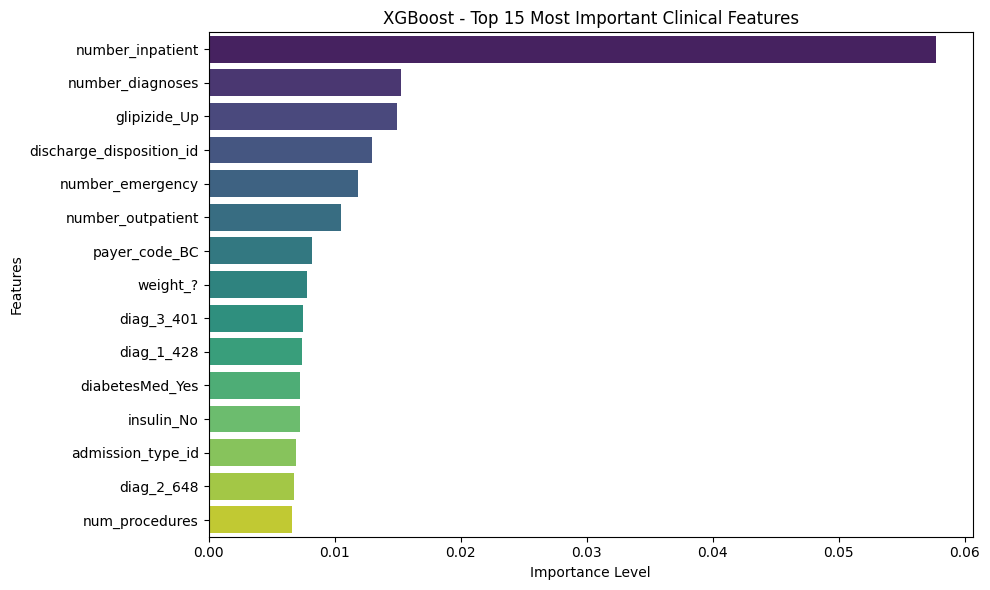

In [7]:
print("STEP 6: FEATURE SELECTION AND DIMENSIONALITY REDUCTION")
# Let's get the feature importances of our best model, XGBoost
best_model = models["XGBoost"]
importances = best_model.feature_importances_

# Sorting features by importance and selecting the top 50
feature_names = X_train_smote.columns
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)
top_50_features = feature_imp_df['Feature'].head(50).tolist()

print(f"Top 50 most important features selected out of 4395 total features.")

# Let's filter the data with only these 50 features
X_train_fs = X_train_smote[top_50_features]
X_test_fs = X_test[top_50_features]

# Let's train our new and lightweight model
xgb_fs = XGBClassifier(random_state=42, eval_metric='logloss')

start_time = time.time()
xgb_fs.fit(X_train_fs, y_train_smote)
train_time_fs = time.time() - start_time

y_pred_fs = xgb_fs.predict(X_test_fs)
acc_fs = accuracy_score(y_test, y_pred_fs)

print("\nFEATURE SELECTION COMPARISON ---")
print(f"Training Time with All Features (4395): {results[4]['Training Time (s)']} seconds")
print(f"Training Time with Only Top 50 Features: {train_time_fs:.4f} seconds")
print(f"Accuracy with All Features: {results[4]['Accuracy']}")
print(f"Accuracy with Only Top 50 Features: % {acc_fs*100:.2f}")

# Let's visualize the top 15 features
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_imp_df.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('XGBoost - Top 15 Most Important Clinical Features')
plt.xlabel('Importance Level')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [8]:
import joblib

# 1. Saving our champion model XGBoost
joblib.dump(models["XGBoost"], '../data/processed/xgboost_champion_model.pkl')

# 2. Saving the exact list and order of 4395 columns to prevent the GUI from crashing
joblib.dump(X_train_smote.columns.tolist(), '../data/processed/model_columns.pkl')

print("Champion model and column map successfully saved! Ready for GUI.")

Champion model and column map successfully saved! Ready for GUI.


Training the model with imbalanced data before SMOTE...


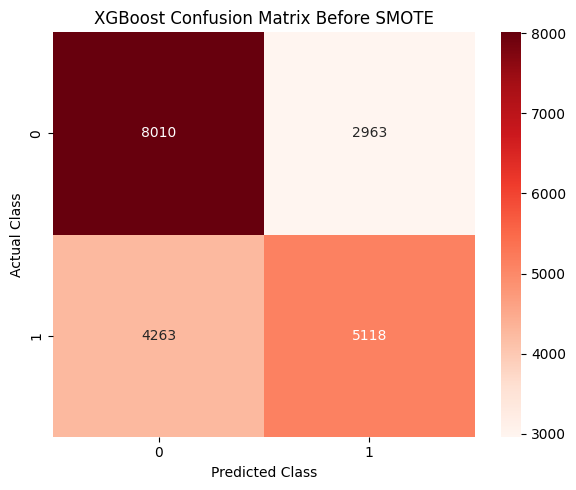

Image saved as 'confusion_before.png'!


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from xgboost import XGBClassifier

# 1. Train XGBoost with data BEFORE SMOTE (imbalanced)
print("Training the model with imbalanced data before SMOTE...")
xgb_imbalanced = XGBClassifier(eval_metric='logloss', random_state=42)
xgb_imbalanced.fit(X_train, y_train)

# 2. Make predictions on the test set
y_pred_imbalanced = xgb_imbalanced.predict(X_test)

# 3. Calculate the Confusion Matrix
cm_before = confusion_matrix(y_test, y_pred_imbalanced)

# 4. Visualization and Saving
plt.figure(figsize=(6, 5))
sns.heatmap(cm_before, annot=True, fmt='d', cmap='Reds')
plt.title('XGBoost Confusion Matrix Before SMOTE')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.tight_layout()

# Saves the image directly to your computer
plt.savefig('confusion_before.png', dpi=300)
plt.show()

print("Image saved as 'confusion_before.png'!")